In [12]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

In [13]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [14]:
chrom = 22

In [15]:
PATH_data = f"../../../../mnt/d/swampy_data/genotype/reduced/{chrom}"

In [16]:
os.listdir(PATH_data)

['0_0_815_0_maf_0.01_0.016.pkl',
 '0_1_800_0_maf_0.01_0.016.pkl',
 '0_2_1200_0_maf_0.01_0.016.pkl',
 '0_3_802_0_maf_0.01_0.016.pkl',
 '0_4_1200_0_maf_0.01_0.016.pkl',
 '0_5_1183_0_maf_0.01_0.016.pkl',
 '0_6_800_0_maf_0.01_0.016.pkl',
 '0_7_800_0_maf_0.01_0.016.pkl',
 '0_8_1200_0_maf_0.01_0.016.pkl',
 '0_9_1200_0_maf_0.01_0.016.pkl',
 '1_0_961_1_maf_0.016_0.023.pkl',
 '1_1_1200_1_maf_0.016_0.023.pkl',
 '1_2_1200_1_maf_0.016_0.023.pkl',
 '1_3_1039_1_maf_0.016_0.023.pkl',
 '1_4_1200_1_maf_0.016_0.023.pkl',
 '1_5_800_1_maf_0.016_0.023.pkl',
 '1_6_1200_1_maf_0.016_0.023.pkl',
 '1_7_800_1_maf_0.016_0.023.pkl',
 '1_8_800_1_maf_0.016_0.023.pkl',
 '1_9_800_1_maf_0.016_0.023.pkl',
 '2_0_947_2_maf_0.023_0.035.pkl',
 '2_1_1183_2_maf_0.023_0.035.pkl',
 '2_2_1200_2_maf_0.023_0.035.pkl',
 '2_3_800_2_maf_0.023_0.035.pkl',
 '2_4_1200_2_maf_0.023_0.035.pkl',
 '2_5_1087_2_maf_0.023_0.035.pkl',
 '2_6_1183_2_maf_0.023_0.035.pkl',
 '2_7_800_2_maf_0.023_0.035.pkl',
 '2_8_800_2_maf_0.023_0.035.pkl',
 '2_9_800

In [17]:
mafs = []
for f in os.listdir(PATH_data):
    mafs.append(float(f.split("_maf_")[1].split("_")[0]))
mafs = list(set(mafs))
mafs.sort()

In [18]:
mafs

[0.01,
 0.016,
 0.023,
 0.035,
 0.049,
 0.067,
 0.091,
 0.12,
 0.16,
 0.21,
 0.26,
 0.32,
 0.38]

In [19]:
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [20]:
for maf in mafs:
    file_name = [f for f in os.listdir(PATH_data) if f.split("_maf_")[1].split("_")[0] == str(maf)]
    for file in file_name:
        PATH_mini_dim = f"../../../../mnt/d/swampy_data/genotype/reduced/{chrom}/{file}"
        nr = file.split('_')[1]
        dim = pd.read_pickle(PATH_mini_dim)
        humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
        humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']

/tmp/ipykernel_811/2664679898.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/2664679898.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fram

/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/2664679898.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fram

/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/2664679898.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fram

/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/2664679898.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/2664679898.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fram

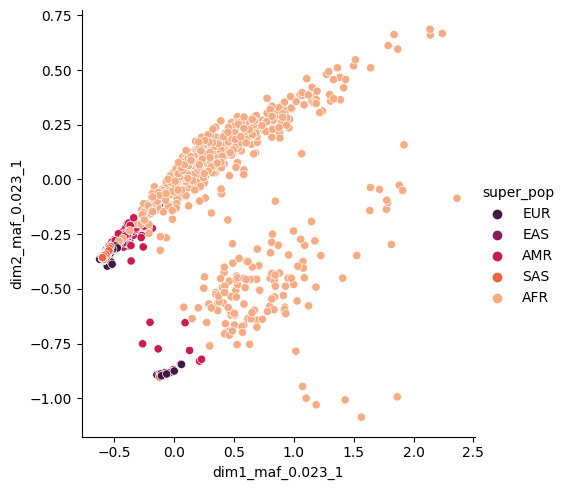

In [23]:
nr = 2
nr_segs = 1
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{mafs[nr]}_{nr_segs}", y=f"dim2_maf_{mafs[nr]}_{nr_segs}",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

In [24]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
for maf in mafs:
    file_name = [f for f in os.listdir(PATH_data) if f.split("_maf_")[1].split("_")[0] == str(maf)]
    for file in file_name:
        PATH_mini_dim = f"../../../../mnt/d/swampy_data/genotype/reduced/{chrom}/{file}"
        nr = file.split('_')[1]
        dim = pd.read_pickle(PATH_mini_dim)
        humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
        humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
        humans[f"pheno_maf_{maf}_{nr}"] = np.round(dim['dim1'] + dim['dim2'],3)

/tmp/ipykernel_811/1513536519.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/1513536519.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/1513536519.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

/tmp/ipykernel_811/1513536519.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/1513536519.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/1513536519.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

/tmp/ipykernel_811/1513536519.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/1513536519.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/1513536519.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

/tmp/ipykernel_811/1513536519.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim1_maf_{maf}_{nr}"] = dim['dim1']
/tmp/ipykernel_811/1513536519.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"dim2_maf_{maf}_{nr}"] = dim['dim2']
/tmp/ipykernel_811/1513536519.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

In [25]:
humans.to_pickle('./data/phenotype/humans_maf_popstrat.pkl')

In [26]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01_0,dim2_maf_0.01_0,pheno_maf_0.01_0,dim1_maf_0.01_1,dim2_maf_0.01_1,...,pheno_maf_0.38_6,dim1_maf_0.38_7,dim2_maf_0.38_7,pheno_maf_0.38_7,dim1_maf_0.38_8,dim2_maf_0.38_8,pheno_maf_0.38_8,dim1_maf_0.38_9,dim2_maf_0.38_9,pheno_maf_0.38_9
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.375,-0.443677,-0.035165,...,0.798,1.161069,-1.495549,-0.334,-0.949972,1.813149,0.863,-1.171391,2.553751,1.382
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443,-0.446558,-0.046905,...,-1.951,0.775375,-1.270812,-0.495,1.337061,1.534934,2.872,-1.564318,0.682684,-0.882
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.771,-0.446295,-0.045300,...,-0.305,-0.104672,0.065098,-0.040,1.284260,1.562281,2.847,-1.201526,0.876214,-0.325
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431,-0.446558,-0.046905,...,-1.274,0.524489,-1.341814,-0.817,1.590940,1.699035,3.290,-2.154419,0.918490,-1.236
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.451,-0.446558,-0.046905,...,-1.597,1.043540,-1.507435,-0.464,3.186151,0.109423,3.296,-0.814364,-0.168550,-0.983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037,-0.446558,-0.046905,...,0.524,-0.850039,0.270451,-0.580,0.878573,0.917069,1.796,0.617828,-0.473264,0.145
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.576,-0.446558,-0.046905,...,-0.352,-1.235123,0.222965,-1.012,2.338984,0.123233,2.462,0.148965,-0.619124,-0.470
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.494,-0.412680,-0.066426,...,0.751,-0.907650,0.232175,-0.675,-1.234109,1.443456,0.209,1.212882,0.247591,1.460
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.485,-0.446558,-0.046905,...,-0.579,0.223853,-1.235748,-1.012,-0.798232,1.020149,0.222,2.321041,0.463230,2.784
